# Performance tests ArrayDeque versions

In [1]:
import time
import random

def end_ops_deque(cls, n, ops):
    """
    Mixed operations test for Deque variants.
    Without indexing ("OrderedDeque() does not implement this")

    Operations distribution:
    - 25%: add_first
    - 25%: add_last
    - 25%: remove_first
    - 25%: remove_last
    """
    d = cls()

    # Initial population
    for i in range(n):
        d.add_last(i)

    start = time.time()

    for _ in range(ops):
        r = random.random()

        if r < 0.25:
            # add_first
            d.add_first(random.randint(-1000, 1000))

        elif r < 0.50:
            # add_last
            d.add_last(random.randint(-1000, 1000))

        elif r < 0.75:
            # remove_first
            if d.size > 0:
                d.remove_first()

        else:
            # remove_last
            if d.size > 0:
                d.remove_last()

    return time.time() - start

In [2]:
from implementations.array_based import (
    ArrayDeque,
    Treque,
    NoModDeque,
    OrderedDeque,
)

rows = []

for n in [1000, 5000, 10000, 50_000]:
    rows.append({
        "n iterations": n,
        "array-deque": end_ops_deque(ArrayDeque, n, 5000),
        "treque": end_ops_deque(Treque, n, 5000),
        "nomod-deque": end_ops_deque(NoModDeque, n, 5000),
        "ordered-deque": end_ops_deque(OrderedDeque, n, 5000),
    })

In [3]:
import pandas as pd


bench_results = pd.DataFrame(rows)
bench_results = bench_results.set_index("n iterations")
bench_results = bench_results.T
bench_results = bench_results.rename_axis("deque-versions", axis="rows")
bench_results

n iterations,1000,5000,10000,50000
deque-versions,,,,
array-deque,0.004591,0.003404,0.003432,0.003281
treque,0.003586,0.003526,0.003626,0.003520
nomod-deque,0.003306,0.003025,0.003041,0.003025
ordered-deque,0.001749,0.001731,0.001706,0.001703


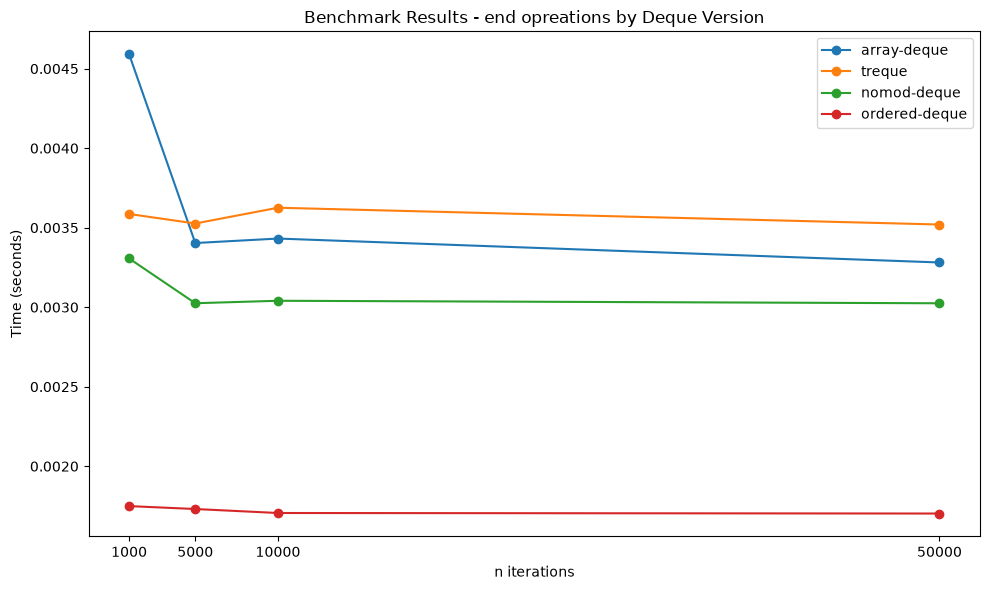

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for version in bench_results.index:
    plt.plot(bench_results.columns, bench_results.loc[version], marker='o', label=version)

plt.xlabel('n iterations')
plt.ylabel('Time (seconds)')
plt.title('Benchmark Results - end opreations by Deque Version')
plt.legend()
plt.xticks(bench_results.columns)
plt.tight_layout()
plt.show()

In [5]:
def index_ops_deque(cls, n, ops):
    """
    Indexed operations test for Deque variants.
    Only uses add(i, x) and remove(i) — tests the indexing path,
    which is where the balancing/amortization shows up.

    Operations distribution:
    - 50%: add(i, x)     with i in [0, size]
    - 50%: remove(i)     with i in [0, size-1]
    """
    d = cls()

    # Initial population (setup, not timed)
    for i in range(n):
        d.add_last(i)

    start = time.time()

    for _ in range(ops):
        r = random.random()

        if r < 0.50:
            # add(i, x) — index may equal size (append position)
            i = random.randrange(d.size + 1)
            d.add(i, random.randint(-1000, 1000))

        else:
            # remove(i)
            if d.size > 0:
                i = random.randrange(d.size)
                d.remove(i)

    return time.time() - start

In [6]:
rows = []

for n in [1000, 5000, 10000, 50_000]:
    rows.append({
        "n iterations": n,
        "array-deque": index_ops_deque(ArrayDeque, n, 2000),
        "treque": index_ops_deque(Treque, n, 2000),
        "nomod-deque": index_ops_deque(NoModDeque, n, 2000),
    })

bench_results = pd.DataFrame(rows)
bench_results = bench_results.set_index("n iterations")
bench_results = bench_results.T
bench_results = bench_results.rename_axis("deque-versions", axis="rows")
bench_results

n iterations,1000,5000,10000,50000
deque-versions,,,,
array-deque,0.099917,0.455016,0.869759,4.432864
treque,0.044263,0.208182,0.451160,2.124439
nomod-deque,0.109888,0.510962,1.025055,5.257479


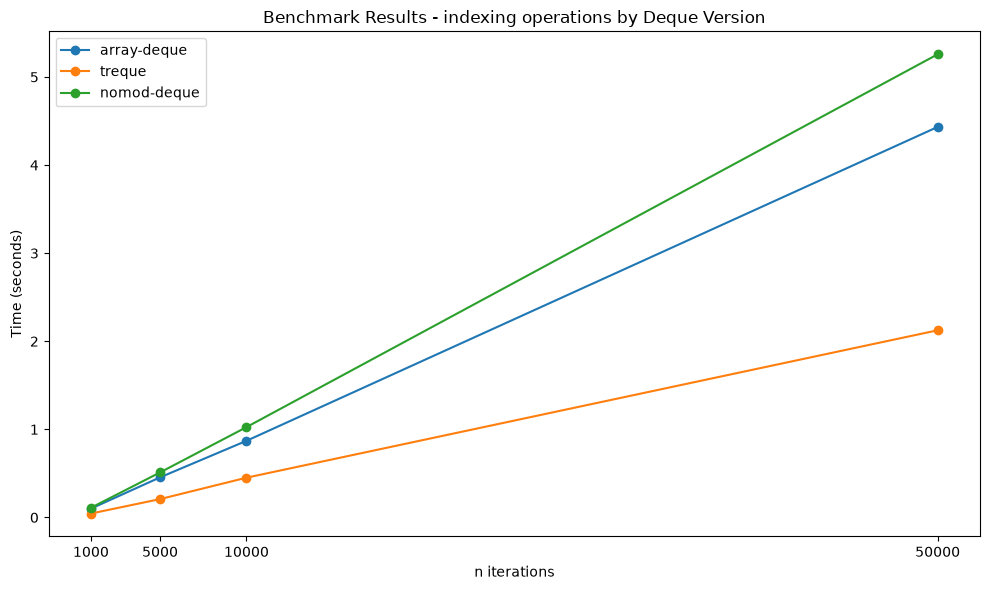

In [7]:
plt.figure(figsize=(10, 6))

for version in bench_results.index:
    plt.plot(bench_results.columns, bench_results.loc[version], marker='o', label=version)

plt.xlabel('n iterations')
plt.ylabel('Time (seconds)')
plt.title('Benchmark Results - indexing operations by Deque Version')
plt.legend()
plt.xticks(bench_results.columns)
plt.tight_layout()
plt.show()